## GITIII vs InterScale

MSE Loss

In [1]:
import os

# LRZ home
if os.path.exists("/dss/dsshome1/05/di93tig"):
    print('LRZ cluster')
    CLUSTER = 'LRZ'
    BASE_DIR_REPO = "/dss/dsshome1/05/di93tig/1_projects/InterScale_reproducibility"
    BASE_DIR_PROJECT = "/dss/dssfs03/tumdss/pn36po/pn36po-dss-0002/di93tig/Projects/A3_InterScale"
elif os.path.exists("/home/icb/francesca.drummer/"):
    print('HPC cluster')
    CLUSTER = 'HPC'
    BASE_DIR_REPO = "/home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility"
    BASE_DIR_PROJECT = ""
else:
    print('unkown')
    CLUSTER = 'unknown'

DATA = "melton25"

HPC cluster


In [2]:
! pwd

/home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/notebooks/melton_jimenez_25


In [4]:
import sys
from pathlib import Path

project_root = Path(BASE_DIR_REPO)
print(project_root)
sys.path.insert(0, str(project_root))

import pandas as pd
import matplotlib.pyplot as plt
from src.wandb import plot_mse_per_celltype, plot_cosine_sim_comparison
from src.wandb import Wandb_evaluation, plot_f1_across_seeds

/home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility


### Reconstruction MSE per cell type

Per-cell-type reconstruction error of InterScale vs. GITIII.

Note that the error bars have a different meaning per model:
- **InterScale**: sd across 5 training runs (seeds)
- **GITIII**: sd across cells (single run)

In [4]:
CSV_PATH = os.path.join(
    BASE_DIR_REPO,
    "figures", DATA, "reconstruction_per_celltype",
    "interscale_vs_gitiii_per_celltype.csv",
)

df_mse = pd.read_csv(CSV_PATH)
df_mse

,cell_type,InterScale_mse,InterScale_sd_across_5_runs,InterScale_fvu,GITIII_mse,GITIII_sd_across_cells,n_cells
0,Acinar,0.046131,0.002557,1.211271,0.033714,0.014061,183994
1,Beta,0.046381,0.002776,0.612908,0.033061,0.011959,9023
2,Alpha,0.048171,0.002239,0.602739,0.036031,0.014270,10315
3,Endocrine,0.052992,0.002922,1.028999,0.037123,0.013196,3656
4,Ductal,0.066639,0.000839,1.151988,0.050577,0.019264,127800
5,Endothelial,0.067307,0.001903,1.148549,0.051786,0.018742,8492
6,Fibroblasts,0.070032,0.002273,1.104645,0.054159,0.020502,24852
7,Immune,0.081510,0.002090,1.098175,0.061581,0.019452,14479
8,Mast,0.104921,0.002889,1.016518,0.086318,0.020839,2949


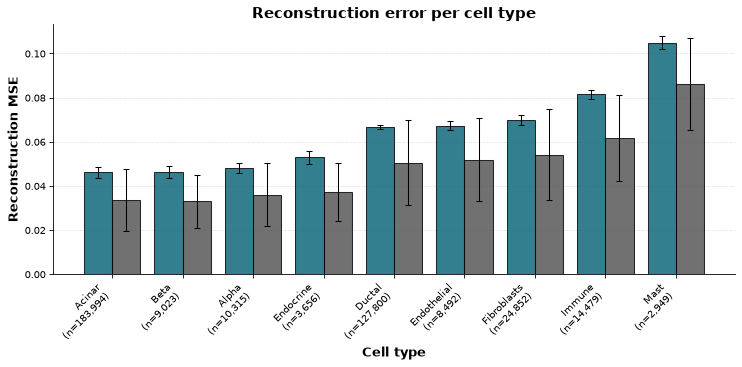

model
GITIII             GITIII_sd_across_cells
InterScale    InterScale_sd_across_5_runs


In [5]:
fig, ax, plot_data = plot_mse_per_celltype(
    CSV_PATH,
    BASE_DIR_REPO=BASE_DIR_REPO,
    models=("InterScale", "GITIII"),
    sort_by="InterScale",
    figsize=(10, 5),
    annotate_n_cells=True,
    save_path=f"{DATA}/reconstruction_per_celltype/mse_per_celltype_interscale_vs_gitiii",
)

## InterScale vs. Steamboat and AMICI

Cosine similarity between predicted and observed expression, one plot per dataset.

For the InterScale variants only the **best of the 3 seeds** (40, 42, 44) is shown;
Steamboat and AMICI were run once each. Every bar is therefore a single run and
there are no error bars. AMICI was only run on Melton & Jimenez 2025.

In [12]:
COMBINED_CSV = os.path.join(
    BASE_DIR_REPO,
    "figures", DATA, "reconstruction_per_celltype",
    "combined_results.csv",
)

df_combined = pd.read_csv(COMBINED_CSV)
df_combined

,model,dataset,cell,epochs,train_runtime_sec,train_vram_peak_gb,train_ram_peak_gb,cosine_sim,seed
0,Amici,meltonjimenez_25,104816,36,1512.284027,0.432711,6.726273,0.699800,NaN
1,Interscale_Dual,legnini_23,43114,28,62.106907,4.012114,2.455864,0.441402,40.0
2,Interscale_Dual,legnini_23,43114,35,75.725096,4.099230,2.527615,0.468706,42.0
3,Interscale_Dual,legnini_23,43114,27,65.844926,4.011505,2.433750,0.393237,44.0
4,Interscale_Dual,meltonjimenez_25,104816,20,182.751398,1.621934,3.992405,0.196815,40.0
5,Interscale_Dual,meltonjimenez_25,104816,23,227.412728,1.676398,3.989365,0.367129,42.0
6,Interscale_Dual,meltonjimenez_25,104816,20,192.380691,1.665712,3.989689,0.517185,44.0
7,Interscale_Global_PCA,legnini_23,43114,25,85.615504,3.865488,2.284954,0.104116,40.0
8,Interscale_Global_PCA,legnini_23,43114,28,90.569538,3.831344,2.296555,0.365770,42.0
9,Interscale_Global_PCA,legnini_23,43114,28,89.664035,3.862772,2.290451,0.325093,44.0


In [ ]:
fig, ax, best_melton = plot_cosine_sim_comparison(
    COMBINED_CSV,
    dataset="meltonjimenez_25",
    BASE_DIR_REPO=BASE_DIR_REPO,
    save_path=f"{DATA}/reconstruction_per_celltype/cosine_sim_meltonjimenez_25",
)

In [ ]:
fig, ax, best_legnini = plot_cosine_sim_comparison(
    COMBINED_CSV,
    dataset="legnini_23",
    BASE_DIR_REPO=BASE_DIR_REPO,
    save_path=f"{DATA}/reconstruction_per_celltype/cosine_sim_legnini_23",
)